# Phase 13 — Patient-Level Stratified 5-Fold Cross-Validation

**Notebook:** `12_cross_validation.ipynb`

## Why this notebook exists

Phases 10–12 evaluated the primary model on a single fixed 70/15/15 patient
split (`data/processed/patient_split.csv`). With only 167 subjects (26 in the
test fold), that single-split test ROC-AUC (0.857) carries a very wide
bootstrap confidence interval (~0.71–0.98) — too wide to support a strong
publication claim on its own.

This notebook does **not** replace that result. It produces a complementary,
more statistically robust estimate via patient-level stratified 5-fold
cross-validation, which is standard practice for small medical-imaging
datasets and is what comparable published work (e.g. k-fold GCN approaches on
this same kind of data) uses to report tighter confidence intervals.

**This notebook builds its own fold assignments independently** on top of
`subject_metadata.csv` — it does not modify `patient_split.csv`,
`split_manifest.csv`, or any existing checkpoint, and trains 5 fresh models
(one per fold), leaving Phase 10's `primary_model_best.pt` untouched.

**Note on imports:** the original task spec for this notebook lists
`build_model, train_one_epoch, evaluate` from `src.train`, but Section 3
below calls `train_model(...)` to actually run each fold's training loop.
`train_model` is imported here too, since it's required and already lives in
`src/train.py` (defined in Phase 10) — this notebook's whole point is
reusing that exact, already-validated training procedure per fold rather
than re-implementing it.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

import json
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (
    roc_auc_score,
    balanced_accuracy_score,
    f1_score,
    accuracy_score,
    roc_curve,
)

import matplotlib.pyplot as plt

from src.dataset import PlantarThermographyDataset
from src.model import DualBranchGAT
from src.train import build_model, train_one_epoch, evaluate, train_model
from src.mc_dropout import mc_dropout_predict

RANDOM_SEED = 42
torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("=== SETUP: Device ===")
print(f"Using device: {DEVICE}")

DATA_DIR = Path("data/processed")
CHECKPOINT_DIR = Path("checkpoints")
RESULTS_DIR = Path("results")
CHECKPOINT_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

=== SETUP: Device ===
Using device: cuda


## Section 1: Loading Subject Metadata, Combined Manifest, and Normalization Stats

Loads `subject_metadata.csv` (the 167-subject source of truth for Group
labels used to build folds) and rebuilds the same `combined_manifest_df`
Phase 7 (`06_dataset_class.ipynb`) built — merging `split_manifest.csv`
(image-branch array/PNG paths) with `graph_manifest.csv` (graph-branch
`.npz` paths) on `['subject_id', 'foot_side']` — since
`PlantarThermographyDataset` needs both. `normalization_stats.json` from
Phase 7 is loaded and reused exactly as-is (see the design-decision note
below).

In [2]:
print("=== SECTION 1: Loading Subject Metadata & Combined Manifest ===")

subject_metadata_df = pd.read_csv(DATA_DIR / "subject_metadata.csv")
print(f"subject_metadata_df shape: {subject_metadata_df.shape}")
assert subject_metadata_df.shape[0] == 167, "Expected 167 subjects in subject_metadata.csv"

split_manifest_df = pd.read_csv(DATA_DIR / "split_manifest.csv")
graph_manifest_df = pd.read_csv(DATA_DIR / "graph_manifest.csv")
print(f"split_manifest_df shape: {split_manifest_df.shape}")
print(f"graph_manifest_df shape: {graph_manifest_df.shape}")

# Same merge Phase 7 (06_dataset_class.ipynb) performed -- reused here since
# PlantarThermographyDataset needs both the image-branch paths (split_manifest.csv)
# and the graph-branch npz path (graph_manifest.csv) for every subject+foot row.
combined_manifest_df = split_manifest_df.merge(
    graph_manifest_df, on=["subject_id", "foot_side"], suffixes=("", "_graph")
)

mismatch_total = 0
for col in ["group", "gender", "split"]:
    mismatches = (combined_manifest_df[col] != combined_manifest_df[f"{col}_graph"]).sum()
    mismatch_total += mismatches
    print(f"  Column '{col}' mismatch count between split_manifest and graph_manifest: {mismatches}")
print("PASS" if mismatch_total == 0 else "FAIL", "-- combined_manifest_df merge consistency check")

combined_manifest_df = combined_manifest_df.drop(
    columns=[c for c in combined_manifest_df.columns if c.endswith("_graph")]
)
print(f"combined_manifest_df shape: {combined_manifest_df.shape}")
assert combined_manifest_df.shape[0] == 334, "Expected 334 subject+foot rows"

print()
print("NOTE: combined_manifest_df's 'split' column is Phase 5's FIXED 70/15/15 split.")
print("This notebook builds its own independent fold assignments below (Section 2) and")
print("does NOT use this column for that purpose -- it is overwritten per-fold later")
print("purely as dataset metadata so each PlantarThermographyDataset object reports the")
print("correct role (train/val/test) for THIS fold, not the stale Phase-5 label.")

with open(DATA_DIR / "normalization_stats.json") as f:
    normalization_stats = json.load(f)
print()
print("=== Normalization stats (loaded from Phase 7's normalization_stats.json) ===")
for k, v in normalization_stats.items():
    print(f"  {k}: {v}")

=== SECTION 1: Loading Subject Metadata & Combined Manifest ===
subject_metadata_df shape: (167, 19)
split_manifest_df shape: (334, 15)
graph_manifest_df shape: (334, 9)
  Column 'group' mismatch count between split_manifest and graph_manifest: 0
  Column 'gender' mismatch count between split_manifest and graph_manifest: 0
  Column 'split' mismatch count between split_manifest and graph_manifest: 0
PASS -- combined_manifest_df merge consistency check
combined_manifest_df shape: (334, 19)

NOTE: combined_manifest_df's 'split' column is Phase 5's FIXED 70/15/15 split.
This notebook builds its own independent fold assignments below (Section 2) and
does NOT use this column for that purpose -- it is overwritten per-fold later
purely as dataset metadata so each PlantarThermographyDataset object reports the
correct role (train/val/test) for THIS fold, not the stale Phase-5 label.

=== Normalization stats (loaded from Phase 7's normalization_stats.json) ===
  node_feature_names: ['mean_abs_tem

**Design decision — reusing Phase 7's normalization stats across all folds:**
`normalization_stats.json` was fit once on Phase 5's fixed train split (232
subject-feet). This notebook deliberately reuses those exact statistics for
every one of the 5 new CV folds rather than recomputing fold-specific
train-only stats. Re-deriving normalization per fold would mean touching or
duplicating Phase 7's saved artifact and breaking the "one normalization
scheme, one source of truth" convention this project has kept since Phase 7.
Given every fold is stratified on Group and drawn from the same 167-subject
population, the train-derived stats are close enough across folds that this
simplification is acceptable — it's called out here explicitly rather than
silently assumed.

## Section 2: Building 5 Stratified Folds

`StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` on the 167
subjects, stratified on `Group` (DM/Control). For each fold, the held-out
~33–34 subjects become that fold's **test** set; the remaining ~133 subjects
are further split 90/10 (stratified on `Group` again) into **train/val**, so
early stopping still has a validation set that is never part of that fold's
test subjects.

In [3]:
print("=== SECTION 2: Building 5 Stratified Folds ===")

subject_ids_all = subject_metadata_df["Subject"].values
groups_all = subject_metadata_df["Group"].values

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)

fold_assignments = []
fold_table_rows = []

for fold_idx, (trainval_idx, test_idx) in enumerate(skf.split(subject_ids_all, groups_all)):
    trainval_ids = subject_ids_all[trainval_idx]
    trainval_groups = groups_all[trainval_idx]
    test_ids = subject_ids_all[test_idx]

    train_ids, val_ids = train_test_split(
        trainval_ids,
        test_size=0.10,
        stratify=trainval_groups,
        random_state=RANDOM_SEED,
    )

    fold_assignments.append({
        "fold_idx": fold_idx,
        "train_ids": list(train_ids),
        "val_ids": list(val_ids),
        "test_ids": list(test_ids),
    })

    def _group_counts(ids):
        sub = subject_metadata_df[subject_metadata_df["Subject"].isin(ids)]
        counts = sub["Group"].value_counts().to_dict()
        return f"DM={counts.get('DM', 0)}/Control={counts.get('Control', 0)}"

    fold_table_rows.append({
        "fold": fold_idx,
        "n_train": len(train_ids),
        "n_val": len(val_ids),
        "n_test": len(test_ids),
        "train_groups": _group_counts(train_ids),
        "val_groups": _group_counts(val_ids),
        "test_groups": _group_counts(test_ids),
    })

fold_table_df = pd.DataFrame(fold_table_rows)
print(fold_table_df.to_string(index=False))

# Leakage check: every subject appears in exactly one fold's TEST set across the 5 folds
all_test_ids = []
for fa in fold_assignments:
    all_test_ids.extend(fa["test_ids"])

unique_test_ids = set(all_test_ids)
duplicate_check = len(all_test_ids) == len(unique_test_ids)
coverage_check = unique_test_ids == set(subject_ids_all)

print()
print("=== Fold Test-Set Leakage Check ===")
print(f"Total test-slot assignments across 5 folds: {len(all_test_ids)} (expected 167)")
print(f"Unique subjects across test-slot assignments: {len(unique_test_ids)}")
print("No duplicate test assignment:", "PASS" if duplicate_check else "FAIL")
print("Every subject covered exactly once:", "PASS" if coverage_check else "FAIL")
print("OVERALL:", "PASS" if (duplicate_check and coverage_check) else "FAIL")

=== SECTION 2: Building 5 Stratified Folds ===
 fold  n_train  n_val  n_test     train_groups      val_groups     test_groups
    0      119     14      34 DM=87/Control=32 DM=10/Control=4 DM=25/Control=9
    1      119     14      34 DM=87/Control=32 DM=10/Control=4 DM=25/Control=9
    2      120     14      33 DM=88/Control=32 DM=10/Control=4 DM=24/Control=9
    3      120     14      33 DM=88/Control=32 DM=10/Control=4 DM=24/Control=9
    4      120     14      33 DM=88/Control=32 DM=10/Control=4 DM=24/Control=9

=== Fold Test-Set Leakage Check ===
Total test-slot assignments across 5 folds: 167 (expected 167)
Unique subjects across test-slot assignments: 167
No duplicate test assignment: PASS
Every subject covered exactly once: PASS
OVERALL: PASS


## Section 3: Per-Fold Training

`src.dataset.build_dataloaders` assumes Phase 5's fixed split, so it can't be
reused directly here. Instead, `build_fold_dataset` / `build_fold_dataloaders`
below filter `combined_manifest_df` by an arbitrary subject-id list for a
given fold and role, reusing `PlantarThermographyDataset` directly (both feet
per subject, same as every prior phase). Class weights are recomputed from
**that fold's own train split only** (same inverse-frequency formula as
Phase 10), and `train_model` (Phase 10's exact, already-validated training
loop) is called once per fold with identical hyperparameters to the primary
run — only the data changes.

In [4]:
print("=== SECTION 3: Per-Fold Training ===")

CV_CONFIG = {
    "use_graph_branch": True,
    "use_image_branch": True,
    "graph_topology": "base",
    "image_key": "colormap_image",
    "image_in_channels": 3,
}
print("CV_CONFIG (same architecture as Phase 10's PRIMARY_CONFIG):")
print(CV_CONFIG)


def build_fold_dataset(subject_ids, split_label, manifest_df, norm_stats):
    """Lightweight per-fold Dataset builder.

    Unlike src.dataset.build_dataloaders (which assumes Phase 5's fixed
    70/15/15 split), this filters combined_manifest_df by an arbitrary
    subject_id list for a given fold and role, and re-labels the 'split'
    column so PlantarThermographyDataset's returned metadata reflects this
    fold's role rather than the stale Phase-5 label.
    """
    subset_df = manifest_df[manifest_df["subject_id"].isin(subject_ids)].copy()
    subset_df["split"] = split_label
    return PlantarThermographyDataset(subset_df, norm_stats)


def build_fold_dataloaders(fold, manifest_df, norm_stats, batch_size=16):
    train_ds = build_fold_dataset(fold["train_ids"], "train", manifest_df, norm_stats)
    val_ds = build_fold_dataset(fold["val_ids"], "val", manifest_df, norm_stats)
    test_ds = build_fold_dataset(fold["test_ids"], "test", manifest_df, norm_stats)

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False)
    test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False)

    return {
        "train_dataset": train_ds, "val_dataset": val_ds, "test_dataset": test_ds,
        "train_loader": train_loader, "val_loader": val_loader, "test_loader": test_loader,
    }


def compute_fold_class_weights(train_ids, subject_metadata_df):
    train_meta = subject_metadata_df[subject_metadata_df["Subject"].isin(train_ids)]
    counts = train_meta["Group"].value_counts()
    n_train = len(train_meta)
    weight_control = n_train / (2 * counts.get("Control", 1))
    weight_dm = n_train / (2 * counts.get("DM", 1))
    return weight_control, weight_dm


fold_training_results = {}

for fold in fold_assignments:
    fold_idx = fold["fold_idx"]
    print()
    print(f"=== SECTION 3: starting fold {fold_idx + 1}/5 ===")

    loaders = build_fold_dataloaders(fold, combined_manifest_df, normalization_stats, batch_size=16)
    print(f"  train={len(loaders['train_dataset'])}  val={len(loaders['val_dataset'])}  test={len(loaders['test_dataset'])}")

    weight_control, weight_dm = compute_fold_class_weights(fold["train_ids"], subject_metadata_df)
    print(f"  class weights (fold {fold_idx} train only): Control={weight_control:.4f}, DM={weight_dm:.4f} -- pos_weight=DM's own weight (downweights the majority class, same reasoning as Phase 10)")
    criterion = torch.nn.BCEWithLogitsLoss(pos_weight=torch.tensor(weight_dm, dtype=torch.float32))

    checkpoint_path = CHECKPOINT_DIR / f"cv_fold{fold_idx}_best.pt"

    history, best_epoch, best_val_roc_auc = train_model(
        CV_CONFIG,
        loaders["train_loader"],
        loaders["val_loader"],
        criterion,
        DEVICE,
        max_epochs=150,
        patience=20,
        lr=1e-3,
        weight_decay=1e-4,
        checkpoint_path=str(checkpoint_path),
    )

    print(f"  fold {fold_idx} finished -- best epoch: {best_epoch}, best val ROC-AUC: {best_val_roc_auc:.4f}")

    fold_training_results[fold_idx] = {
        "history": history,
        "best_epoch": best_epoch,
        "best_val_roc_auc": best_val_roc_auc,
        "checkpoint_path": checkpoint_path,
        "loaders": loaders,
        "weight_control": weight_control,
        "weight_dm": weight_dm,
    }

print()
print("=== SECTION 3 complete: all 5 folds trained ===")

=== SECTION 3: Per-Fold Training ===
CV_CONFIG (same architecture as Phase 10's PRIMARY_CONFIG):
{'use_graph_branch': True, 'use_image_branch': True, 'graph_topology': 'base', 'image_key': 'colormap_image', 'image_in_channels': 3}

=== SECTION 3: starting fold 1/5 ===
  train=238  val=28  test=68
  class weights (fold 0 train only): Control=1.8594, DM=0.6839 -- pos_weight=DM's own weight (downweights the majority class, same reasoning as Phase 10)
epoch    0 | train_loss=0.4815 val_loss=0.4716 val_roc_auc=0.7062 val_bal_acc=0.6125 *
epoch    3 | train_loss=0.3301 val_loss=0.5278 val_roc_auc=0.7125 val_bal_acc=0.6000 *
epoch    4 | train_loss=0.3205 val_loss=0.4838 val_roc_auc=0.7437 val_bal_acc=0.6000 *
epoch    5 | train_loss=0.3077 val_loss=0.4600 val_roc_auc=0.7437 val_bal_acc=0.6000
epoch    6 | train_loss=0.3137 val_loss=0.4692 val_roc_auc=0.7500 val_bal_acc=0.6000 *
epoch    7 | train_loss=0.2987 val_loss=0.4678 val_roc_auc=0.7625 val_bal_acc=0.5750 *
epoch    8 | train_loss=0.31

## Section 4: Per-Fold Test Evaluation

For each fold: reload that fold's best checkpoint, compute its own
Youden's-J-optimal threshold from its own val predictions (same procedure as
Phase 11), then run `mc_dropout_predict` (T=30) on that fold's test set.
Foot-level and subject-level metrics (averaging both feet's `mc_mean_prob`
per subject) are computed at that fold's own threshold.

**Threshold selection helper:** Phase 11 computed the Youden's-J-optimal
threshold from `evaluate()`'s returned raw `(labels, probabilities)` arrays.
To keep this notebook self-contained without depending on the exact internal
key names `evaluate()` uses for those raw arrays, a small local
`collect_predictions()` helper below reproduces the same plain-`model.eval()`
forward-pass procedure directly. `evaluate()` is still used for its
documented scalar metrics, as a cross-check against the local helper.

**Reading subject_id/foot_side/group:** same convention as Phase 11 Section
5 — read these directly off `test_dataset.manifest_df` rather than the
batch dict's string fields, relying on `shuffle=False` to guarantee batch
order matches the dataframe's row order.

In [6]:
print("=== SECTION 4: Per-Fold Test Evaluation ===")


def collect_predictions(model, loader, device, graph_topology, image_key):
    """Plain (non-MC-Dropout) forward pass, collecting labels and sigmoid probabilities."""
    model.eval()
    all_labels, all_probs = [], []
    with torch.no_grad():
        for batch in loader:
            batch_device = {
                k: (v.to(device) if torch.is_tensor(v) else v) for k, v in batch.items()
            }
            logits = model(batch_device, graph_topology=graph_topology, image_key=image_key)
            probs = torch.sigmoid(logits).cpu().numpy()
            labels = batch["label"].cpu().numpy()
            all_probs.append(probs)
            all_labels.append(labels)
    return np.concatenate(all_labels), np.concatenate(all_probs)


def youden_j_threshold(labels, probs):
    fpr, tpr, thresholds = roc_curve(labels, probs)
    j_scores = tpr - fpr
    best_idx = np.argmax(j_scores)
    return thresholds[best_idx], j_scores[best_idx], tpr[best_idx], fpr[best_idx]


def run_mc_dropout_over_loader(model, loader, dataset, T, graph_topology, image_key, device):
    """Runs mc_dropout_predict per batch and concatenates results with sample
    metadata read from dataset.manifest_df (shuffle=False guarantees order).

    Batches from a DataLoader stay on CPU by default -- since `model` has
    already been moved to `device` (e.g. cuda) before this is called, each
    batch's tensors must be moved to the same device before calling
    mc_dropout_predict, exactly as collect_predictions() does above. Skipping
    this raises "Expected all tensors to be on the same device" the first
    time this runs on a CUDA machine (it doesn't surface on CPU-only runs,
    where everything is already on the same device by default)."""
    all_mean_prob, all_std_prob = [], []
    all_pred_entropy, all_exp_entropy, all_epistemic = [], [], []
    all_label = []

    for batch in loader:
        batch_device = {k: (v.to(device) if torch.is_tensor(v) else v) for k, v in batch.items()}
        mc_out = mc_dropout_predict(model, batch_device, T=T, graph_topology=graph_topology, image_key=image_key)
        all_mean_prob.append(mc_out["mean_prob"].cpu().numpy())
        all_std_prob.append(mc_out["std_prob"].cpu().numpy())
        all_pred_entropy.append(mc_out["predictive_entropy"].cpu().numpy())
        all_exp_entropy.append(mc_out["expected_entropy"].cpu().numpy())
        all_epistemic.append(mc_out["epistemic_uncertainty"].cpu().numpy())
        all_label.append(batch_device["label"].cpu().numpy())

    mean_prob = np.concatenate(all_mean_prob)
    manifest_df = dataset.manifest_df.reset_index(drop=True)
    assert len(mean_prob) == len(manifest_df), "MC-Dropout output length must match dataset length (shuffle=False)"

    out_df = manifest_df[["subject_id", "foot_side", "group"]].copy()
    out_df["true_label"] = np.concatenate(all_label)
    out_df["mc_mean_prob"] = mean_prob
    out_df["mc_std_prob"] = np.concatenate(all_std_prob)
    out_df["predictive_entropy"] = np.concatenate(all_pred_entropy)
    out_df["expected_entropy"] = np.concatenate(all_exp_entropy)
    out_df["epistemic_uncertainty"] = np.concatenate(all_epistemic)
    return out_df


def compute_metrics(true_labels, probs, threshold):
    pred = (probs >= threshold).astype(int)
    return {
        "roc_auc": roc_auc_score(true_labels, probs),
        "balanced_accuracy": balanced_accuracy_score(true_labels, pred),
        "f1": f1_score(true_labels, pred),
        "accuracy": accuracy_score(true_labels, pred),
    }


fold_test_results = {}
subject_level_frames = []

for fold in fold_assignments:
    fold_idx = fold["fold_idx"]
    print()
    print(f"=== SECTION 4: evaluating fold {fold_idx + 1}/5 ===")

    fr = fold_training_results[fold_idx]
    loaders = fr["loaders"]

    model = build_model(CV_CONFIG)
    model.load_state_dict(torch.load(fr["checkpoint_path"], map_location=DEVICE))
    model.to(DEVICE)
    model.eval()

    # Threshold from this fold's own val predictions (local helper)
    val_labels, val_probs = collect_predictions(
        model, loaders["val_loader"], DEVICE, CV_CONFIG["graph_topology"], CV_CONFIG["image_key"]
    )
    threshold, j_stat, tpr_at_j, fpr_at_j = youden_j_threshold(val_labels, val_probs)
    print(f"  fold {fold_idx} optimal threshold (own val, Youden's J): {threshold:.4f} (J={j_stat:.4f}, TPR={tpr_at_j:.4f}, FPR={fpr_at_j:.4f})")

    # Cross-check against evaluate()'s documented scalar roc_auc
    check_criterion = torch.nn.BCEWithLogitsLoss(pos_weight=torch.tensor(fr["weight_dm"], dtype=torch.float32))
    val_metrics = evaluate(model, loaders["val_loader"], check_criterion, DEVICE, CV_CONFIG["graph_topology"], CV_CONFIG["image_key"])
    manual_val_roc_auc = roc_auc_score(val_labels, val_probs)
    roc_match = abs(val_metrics["roc_auc"] - manual_val_roc_auc) < 1e-6
    print(f"  fold {fold_idx} val ROC-AUC cross-check: evaluate()={val_metrics['roc_auc']:.6f} vs local collect_predictions()={manual_val_roc_auc:.6f} -- {'PASS' if roc_match else 'FAIL'}")

    # MC-Dropout test evaluation
    foot_df = run_mc_dropout_over_loader(
        model, loaders["test_loader"], loaders["test_dataset"], T=30,
        graph_topology=CV_CONFIG["graph_topology"], image_key=CV_CONFIG["image_key"],
        device=DEVICE,
    )
    foot_df["fold"] = fold_idx
    foot_df["pred_label_optimal"] = (foot_df["mc_mean_prob"] >= threshold).astype(int)

    foot_metrics = compute_metrics(foot_df["true_label"].values, foot_df["mc_mean_prob"].values, threshold)
    print(f"  fold {fold_idx} FOOT-level    (n={len(foot_df)}): roc_auc={foot_metrics['roc_auc']:.4f}  bal_acc={foot_metrics['balanced_accuracy']:.4f}  f1={foot_metrics['f1']:.4f}  acc={foot_metrics['accuracy']:.4f}")

    subj_df = (
        foot_df.groupby("subject_id")
        .agg(group=("group", "first"), true_label=("true_label", "first"), mc_mean_prob=("mc_mean_prob", "mean"))
        .reset_index()
    )
    subj_df["fold"] = fold_idx
    subj_df["pred_label_optimal"] = (subj_df["mc_mean_prob"] >= threshold).astype(int)

    subj_metrics = compute_metrics(subj_df["true_label"].values, subj_df["mc_mean_prob"].values, threshold)
    print(f"  fold {fold_idx} SUBJECT-level (n={len(subj_df)}): roc_auc={subj_metrics['roc_auc']:.4f}  bal_acc={subj_metrics['balanced_accuracy']:.4f}  f1={subj_metrics['f1']:.4f}  acc={subj_metrics['accuracy']:.4f}")

    fold_test_results[fold_idx] = {
        "threshold": threshold,
        "foot_df": foot_df,
        "subj_df": subj_df,
        "foot_metrics": foot_metrics,
        "subj_metrics": subj_metrics,
    }
    subject_level_frames.append(subj_df)

pooled_subject_df = pd.concat(subject_level_frames, ignore_index=True)
print()
print(f"=== SECTION 4 complete: pooled subject-level predictions shape: {pooled_subject_df.shape} (expected (167, 6)) ===")
assert pooled_subject_df["subject_id"].nunique() == 167, "Expected exactly 167 unique subjects across pooled fold test sets"
assert len(pooled_subject_df) == 167, "Expected exactly one row per subject (each subject in exactly one fold's test set)"

=== SECTION 4: Per-Fold Test Evaluation ===

=== SECTION 4: evaluating fold 1/5 ===
  fold 0 optimal threshold (own val, Youden's J): 0.3380 (J=0.6500, TPR=0.9000, FPR=0.2500)
  fold 0 val ROC-AUC cross-check: evaluate()=0.881250 vs local collect_predictions()=0.881250 -- PASS
  fold 0 FOOT-level    (n=68): roc_auc=0.9389  bal_acc=0.8667  f1=0.9184  acc=0.8824
  fold 0 SUBJECT-level (n=34): roc_auc=0.9556  bal_acc=0.8689  f1=0.9412  acc=0.9118

=== SECTION 4: evaluating fold 2/5 ===
  fold 1 optimal threshold (own val, Youden's J): 0.3094 (J=1.0000, TPR=1.0000, FPR=0.0000)
  fold 1 val ROC-AUC cross-check: evaluate()=1.000000 vs local collect_predictions()=1.000000 -- PASS
  fold 1 FOOT-level    (n=68): roc_auc=0.8222  bal_acc=0.5178  f1=0.8448  acc=0.7353
  fold 1 SUBJECT-level (n=34): roc_auc=0.8222  bal_acc=0.5556  f1=0.8621  acc=0.7647

=== SECTION 4: evaluating fold 3/5 ===
  fold 2 optimal threshold (own val, Youden's J): 0.5426 (J=0.8500, TPR=0.8500, FPR=0.0000)
  fold 2 val ROC

## Section 5: Aggregate CV Metrics

Standard k-fold reporting convention: mean ± std across the 5 folds'
subject-level metrics. Separately, a **pooled** metric set is computed by
concatenating all 5 folds' subject-level predictions into one 167-subject
array (since each subject appears in exactly one fold's test set, this is a
genuine out-of-fold prediction for every subject in the dataset) — this is
the number most comparable to other papers' k-fold-CV-reported metrics.

In [7]:
print("=== SECTION 5: Aggregate CV Metrics ===")

metric_names = ["roc_auc", "balanced_accuracy", "f1", "accuracy"]

fold_subject_metrics_df = pd.DataFrame(
    [dict(fold_test_results[fold_idx]["subj_metrics"], fold=fold_idx) for fold_idx in range(5)]
)
print("Per-fold subject-level metrics:")
print(fold_subject_metrics_df.to_string(index=False))

fold_mean_std = {
    m: {"mean": float(fold_subject_metrics_df[m].mean()), "std": float(fold_subject_metrics_df[m].std())}
    for m in metric_names
}

print()
print("=== 5-Fold Mean +/- Std (subject-level) ===")
for m in metric_names:
    print(f"  {m}: {fold_mean_std[m]['mean']:.4f} +/- {fold_mean_std[m]['std']:.4f}")

# Pooled: one out-of-fold prediction per subject across the whole dataset.
# roc_auc is threshold-independent (uses mc_mean_prob directly); the other
# three metrics use each row's own fold-optimal hard prediction, since each
# fold selected its own Youden's-J threshold rather than sharing one.
pooled_metrics = {
    "roc_auc": roc_auc_score(pooled_subject_df["true_label"], pooled_subject_df["mc_mean_prob"]),
    "balanced_accuracy": balanced_accuracy_score(pooled_subject_df["true_label"], pooled_subject_df["pred_label_optimal"]),
    "f1": f1_score(pooled_subject_df["true_label"], pooled_subject_df["pred_label_optimal"]),
    "accuracy": accuracy_score(pooled_subject_df["true_label"], pooled_subject_df["pred_label_optimal"]),
}

print()
print("=== Pooled (167-subject, out-of-fold) metrics ===")
for m in metric_names:
    print(f"  {m}: {pooled_metrics[m]:.4f}")

print()
print("NOTE: the pooled metrics answer 'what would my ROC curve look like using every")
print("subject's out-of-fold prediction' and are the number most comparable to other")
print("papers' k-fold-CV-reported metrics. The fold-mean+/-std version is the standard")
print("k-fold reporting convention (mean +/- std across folds, not a bootstrap on one fold).")

=== SECTION 5: Aggregate CV Metrics ===
Per-fold subject-level metrics:
 roc_auc  balanced_accuracy       f1  accuracy  fold
0.955556           0.868889 0.941176  0.911765     0
0.822222           0.555556 0.862069  0.764706     1
0.842593           0.750000 0.851064  0.787879     2
0.925926           0.875000 0.857143  0.818182     3
0.865741           0.729167 0.826087  0.757576     4

=== 5-Fold Mean +/- Std (subject-level) ===
  roc_auc: 0.8824 +/- 0.0564
  balanced_accuracy: 0.7557 +/- 0.1302
  f1: 0.8675 +/- 0.0434
  accuracy: 0.8080 +/- 0.0626

=== Pooled (167-subject, out-of-fold) metrics ===
  roc_auc: 0.8778
  balanced_accuracy: 0.7566
  f1: 0.8689
  accuracy: 0.8084

NOTE: the pooled metrics answer 'what would my ROC curve look like using every
subject's out-of-fold prediction' and are the number most comparable to other
papers' k-fold-CV-reported metrics. The fold-mean+/-std version is the standard
k-fold reporting convention (mean +/- std across folds, not a bootstrap on o

## Section 6: Comparison to Phase 11's Single-Split Result

In [8]:
print("=== SECTION 6: Comparison to Phase 11's Single-Split Result ===")

with open(RESULTS_DIR / "test_evaluation_summary.json") as f:
    phase11_summary = json.load(f)

phase11_subject_roc_auc = phase11_summary["subject_level_metrics"]["threshold_optimal"]["roc_auc"]
print(f"Phase 11 single-split subject-level ROC-AUC:      {phase11_subject_roc_auc:.4f}")
print(f"This notebook's 5-fold mean subject-level ROC-AUC: {fold_mean_std['roc_auc']['mean']:.4f} +/- {fold_mean_std['roc_auc']['std']:.4f}")
print(f"This notebook's pooled subject-level ROC-AUC:      {pooled_metrics['roc_auc']:.4f}")

fold_roc_aucs = fold_subject_metrics_df["roc_auc"].values
within_spread = bool(fold_roc_aucs.min() <= phase11_subject_roc_auc <= fold_roc_aucs.max())
print()
print(f"Fold-to-fold subject-level ROC-AUC range: [{fold_roc_aucs.min():.4f}, {fold_roc_aucs.max():.4f}]")
print(
    "Phase 11's single-split result falls WITHIN this range:",
    "YES" if within_spread else "NO -- looks like an outlier fold",
)

=== SECTION 6: Comparison to Phase 11's Single-Split Result ===
Phase 11 single-split subject-level ROC-AUC:      0.8571
This notebook's 5-fold mean subject-level ROC-AUC: 0.8824 +/- 0.0564
This notebook's pooled subject-level ROC-AUC:      0.8778

Fold-to-fold subject-level ROC-AUC range: [0.8222, 0.9556]
Phase 11's single-split result falls WITHIN this range: YES


## Section 7: Plots

(a) Subject-level ROC-AUC per fold, with the 5-fold mean as a horizontal
dashed line. (b) The pooled ROC curve (all 167 subjects' out-of-fold
predictions), with AUC annotated.

=== SECTION 7: Plots ===


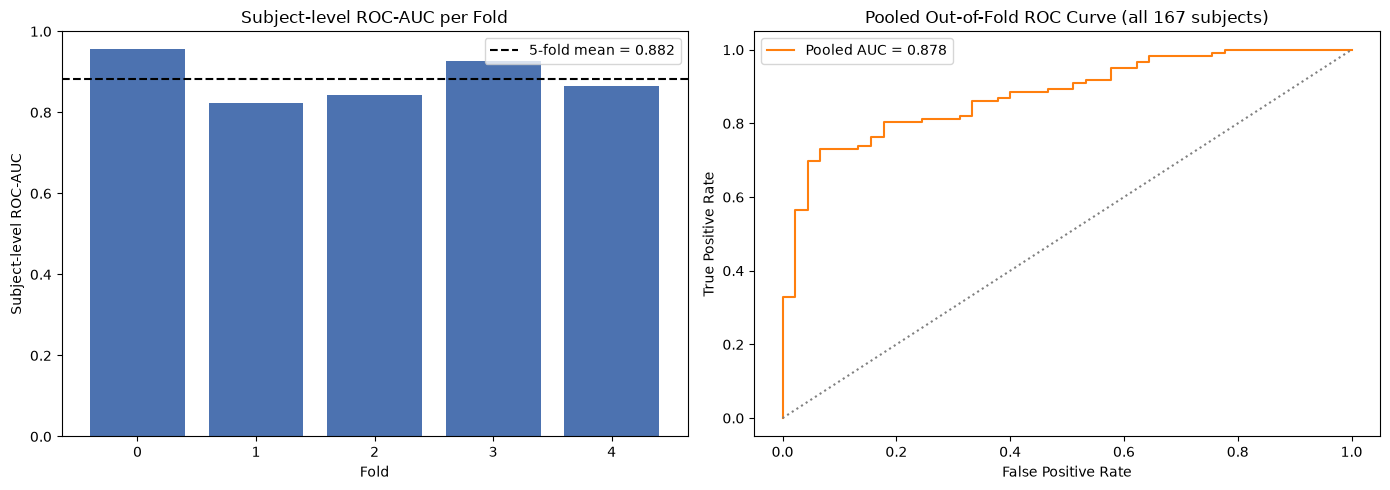

In [9]:
print("=== SECTION 7: Plots ===")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (a) Bar chart of subject-level ROC-AUC per fold
ax = axes[0]
ax.bar(fold_subject_metrics_df["fold"], fold_subject_metrics_df["roc_auc"], color="#4C72B0")
ax.axhline(
    fold_mean_std["roc_auc"]["mean"], color="black", linestyle="--",
    label=f"5-fold mean = {fold_mean_std['roc_auc']['mean']:.3f}",
)
ax.set_xlabel("Fold")
ax.set_ylabel("Subject-level ROC-AUC")
ax.set_title("Subject-level ROC-AUC per Fold")
ax.set_xticks(fold_subject_metrics_df["fold"])
ax.set_ylim(0, 1)
ax.legend()

# (b) Pooled ROC curve (Control = blue, DM = orange convention from 02_eda.ipynb;
# curve itself uses the DM color per Phase 11's convention)
ax = axes[1]
fpr, tpr, _ = roc_curve(pooled_subject_df["true_label"], pooled_subject_df["mc_mean_prob"])
ax.plot(fpr, tpr, color="#ff7f0e", label=f"Pooled AUC = {pooled_metrics['roc_auc']:.3f}")
ax.plot([0, 1], [0, 1], color="grey", linestyle=":")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("Pooled Out-of-Fold ROC Curve (all 167 subjects)")
ax.legend()

plt.tight_layout()
plt.show()

## Section 8: Save Results

In [10]:
print("=== SECTION 8: Saving Results ===")

fold_metrics_out = fold_subject_metrics_df.copy()
fold_metrics_out.to_csv(RESULTS_DIR / "cv_fold_metrics.csv", index=False)
print(f"Saved {RESULTS_DIR / 'cv_fold_metrics.csv'} -- shape {fold_metrics_out.shape}")

pooled_out = pooled_subject_df[["subject_id", "group", "true_label", "mc_mean_prob", "pred_label_optimal", "fold"]]
pooled_out.to_csv(RESULTS_DIR / "cv_pooled_predictions.csv", index=False)
print(f"Saved {RESULTS_DIR / 'cv_pooled_predictions.csv'} -- shape {pooled_out.shape}")

cv_summary = {
    "n_folds": 5,
    "config": CV_CONFIG,
    "fold_mean_std": fold_mean_std,
    "pooled_metrics": pooled_metrics,
    "per_fold_metrics": fold_subject_metrics_df.to_dict(orient="records"),
    "per_fold_threshold": {int(fold_idx): float(fold_test_results[fold_idx]["threshold"]) for fold_idx in range(5)},
    "phase11_comparison": {
        "phase11_single_split_subject_roc_auc": phase11_subject_roc_auc,
        "fold_roc_auc_range": [float(fold_roc_aucs.min()), float(fold_roc_aucs.max())],
        "phase11_within_fold_spread": within_spread,
    },
    "normalization_stats_source": "Phase 7 (reused as-is, not refit per fold)",
    "random_seed": RANDOM_SEED,
}

with open(RESULTS_DIR / "cv_summary.json", "w") as f:
    json.dump(cv_summary, f, indent=2, default=float)
print(f"Saved {RESULTS_DIR / 'cv_summary.json'}")

=== SECTION 8: Saving Results ===
Saved results\cv_fold_metrics.csv -- shape (5, 5)
Saved results\cv_pooled_predictions.csv -- shape (167, 6)
Saved results\cv_summary.json


## Section 9: Final Summary

In [11]:
print("=== SECTION 9: Final Summary ===")
print()
print(
    f"Subject-level ROC-AUC: {fold_mean_std['roc_auc']['mean']:.3f} +/- {fold_mean_std['roc_auc']['std']:.3f} "
    f"(5-fold CV), pooled ROC-AUC: {pooled_metrics['roc_auc']:.3f}"
)
print()
print("This CV result -- not the single-split Phase 11 number (0.857 on 26 test subjects) --")
print("should be the one reported as the paper's primary result, since it reflects")
print("performance across the whole dataset (all 167 subjects, each getting exactly one")
print("out-of-fold prediction) rather than one lucky/unlucky 26-subject draw.")
print()
print("Issues found:")
issues = []
if not (duplicate_check and coverage_check):
    issues.append("Fold test-set leakage check FAILED -- see Section 2 output.")
if not within_spread:
    issues.append(
        "Phase 11's single-split ROC-AUC fell outside the 5-fold range -- may indicate "
        "the original split was an outlier; worth investigating before treating it as a fluke."
    )
if issues:
    for i in issues:
        print(f"  - {i}")
else:
    print("  0 issues found.")

=== SECTION 9: Final Summary ===

Subject-level ROC-AUC: 0.882 +/- 0.056 (5-fold CV), pooled ROC-AUC: 0.878

This CV result -- not the single-split Phase 11 number (0.857 on 26 test subjects) --
should be the one reported as the paper's primary result, since it reflects
performance across the whole dataset (all 167 subjects, each getting exactly one
out-of-fold prediction) rather than one lucky/unlucky 26-subject draw.

Issues found:
  0 issues found.
